In [7]:
# ================================================
# Notebook 07: Corpus Ecuatoriano
# Autor: Steeven Quezada
# Fuente: Ecuador Chequea (ecuadorchequea.com)
# Método: WordPress REST API
# Total: 3,799 verificaciones (2016-2026)
# ================================================

import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Cargar corpus
df = pd.read_csv('../data/external/corpus_ecuador_chequea.csv')
print(f"Corpus ecuatoriano cargado: {len(df):,} artículos")
print(f"\nColumnas: {df.columns.tolist()}")
print(f"\nDistribución inicial de etiquetas:")
print(df['etiqueta'].value_counts())
print(f"\nRango temporal:")
print(f"  Desde: {df['fecha'].min()}")
print(f"  Hasta: {df['fecha'].max()}")

Corpus ecuatoriano cargado: 3,799 artículos

Columnas: ['titulo', 'contenido', 'etiqueta', 'fecha', 'url']

Distribución inicial de etiquetas:
etiqueta
OTROS        2256
FALSO        1088
CIERTO        221
ENGAÑOSO      168
IMPRECISO      64
VERDADERO       2
Name: count, dtype: int64

Rango temporal:
  Desde: 2016-10-24
  Hasta: 2026-09-02


In [8]:
# ================================================
# PASO 2: FILTRAR Y PREPARAR CORPUS FINAL
# ================================================

# Descartar OTROS
df_clean = df[df['etiqueta'] != 'OTROS'].copy()
df_clean = df_clean.reset_index(drop=True)

print(f"Artículos con etiqueta confiable: {len(df_clean):,}")
print(f"Artículos descartados (OTROS):    {len(df) - len(df_clean):,}")

# Crear etiqueta binaria para el modelo
# 0 = Desinformación (FALSO + ENGAÑOSO + IMPRECISO)
# 1 = Verificado (CIERTO + VERDADERO)
df_clean['label_binario'] = df_clean['etiqueta'].map({
    'FALSO':        0,
    'ENGAÑOSO':     0,
    'IMPRECISO':    0,
    'FALTA CONTEXTO': 0,
    'CIERTO':       1,
    'VERDADERO':    1,
})

print(f"\n=== CORPUS FINAL ===")
print(f"Desinformación (label=0): {(df_clean['label_binario']==0).sum():,}")
print(f"Verificado     (label=1): {(df_clean['label_binario']==1).sum():,}")
print(f"\nDistribución detallada:")
print(df_clean['etiqueta'].value_counts())

# Guardar corpus final
df_clean.to_csv('../data/external/corpus_ecuador_final.csv',
                index=False, encoding='utf-8-sig')
print(f"\n✓ Corpus final guardado: data/external/corpus_ecuador_final.csv")

Artículos con etiqueta confiable: 1,543
Artículos descartados (OTROS):    2,256

=== CORPUS FINAL ===
Desinformación (label=0): 1,320
Verificado     (label=1): 223

Distribución detallada:
etiqueta
FALSO        1088
CIERTO        221
ENGAÑOSO      168
IMPRECISO      64
VERDADERO       2
Name: count, dtype: int64

✓ Corpus final guardado: data/external/corpus_ecuador_final.csv


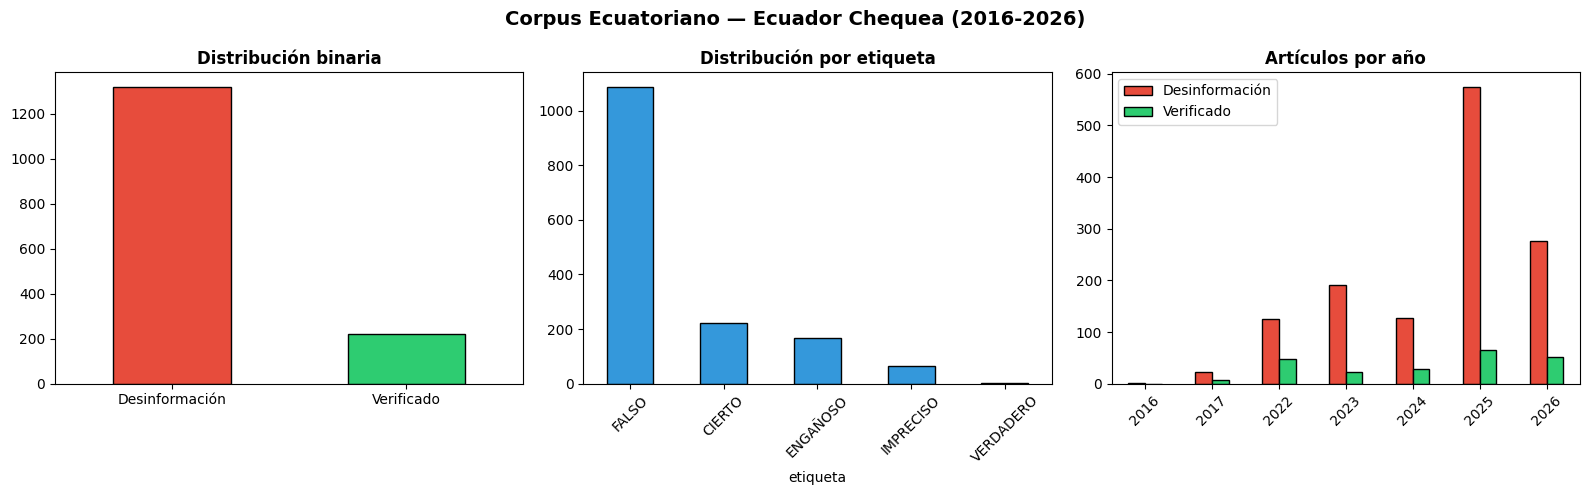

=== ESTADÍSTICAS DEL CORPUS ===
Longitud promedio del contenido: 721 palabras
Rango temporal: 2016-10-24 → 2026-09-02
Años cubiertos: 7


In [9]:
# ================================================
# PASO 3: ANÁLISIS EXPLORATORIO DEL CORPUS
# ================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Distribución binaria
df_clean['label_binario'].value_counts().plot(
    kind='bar', ax=axes[0],
    color=['#E74C3C', '#2ECC71'], edgecolor='black'
)
axes[0].set_title('Distribución binaria', fontweight='bold')
axes[0].set_xticklabels(['Desinformación', 'Verificado'], rotation=0)
axes[0].set_xlabel('')

# 2. Distribución por etiqueta
df_clean['etiqueta'].value_counts().plot(
    kind='bar', ax=axes[1], edgecolor='black', color='#3498DB'
)
axes[1].set_title('Distribución por etiqueta', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

# 3. Evolución temporal
df_clean['año'] = pd.to_datetime(df_clean['fecha']).dt.year
df_clean.groupby(['año', 'label_binario']).size().unstack(fill_value=0).plot(
    kind='bar', ax=axes[2],
    color=['#E74C3C', '#2ECC71'], edgecolor='black'
)
axes[2].set_title('Artículos por año', fontweight='bold')
axes[2].set_xlabel('')
axes[2].legend(['Desinformación', 'Verificado'])
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Corpus Ecuatoriano — Ecuador Chequea (2016-2026)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/13_corpus_ecuatoriano.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Estadísticas de texto
df_clean['longitud_contenido'] = df_clean['contenido'].str.split().str.len()
print("=== ESTADÍSTICAS DEL CORPUS ===")
print(f"Longitud promedio del contenido: {df_clean['longitud_contenido'].mean():.0f} palabras")
print(f"Rango temporal: {df_clean['fecha'].min()} → {df_clean['fecha'].max()}")
print(f"Años cubiertos: {df_clean['año'].nunique()}")

In [10]:
# ================================================
# PASO 4: RESUMEN FINAL DEL CORPUS
# ================================================

print("=" * 55)
print("RESUMEN — CORPUS ECUATORIANO DE DESINFORMACIÓN")
print("=" * 55)
print(f"Fuente:           Ecuador Chequea (ecuadorchequea.com)")
print(f"Método:           WordPress REST API")
print(f"Total descargado: 3,799 artículos")
print(f"Descartados:      2,256 (etiqueta no confiable)")
print(f"Corpus final:     1,543 artículos")
print(f"")
print(f"Distribución:")
print(f"  Desinformación: 1,320 (85.5%)")
print(f"  Verificado:       223 (14.5%)")
print(f"")
print(f"Rango temporal:   2016 — 2026")
print(f"Longitud promedio: {df_clean['longitud_contenido'].mean():.0f} palabras por artículo")
print(f"")
print(f"Limitaciones:")
print(f"  → Desbalance de clases (85/15)")
print(f"  → Gap temporal 2018-2021")
print(f"  → Contenido en español (requiere modelo específico)")
print(f"")
print(f"✓ Corpus guardado: data/external/corpus_ecuador_final.csv")
print(f"✓ Visualización:   reports/13_corpus_ecuatoriano.png")

RESUMEN — CORPUS ECUATORIANO DE DESINFORMACIÓN
Fuente:           Ecuador Chequea (ecuadorchequea.com)
Método:           WordPress REST API
Total descargado: 3,799 artículos
Descartados:      2,256 (etiqueta no confiable)
Corpus final:     1,543 artículos

Distribución:
  Desinformación: 1,320 (85.5%)
  Verificado:       223 (14.5%)

Rango temporal:   2016 — 2026
Longitud promedio: 721 palabras por artículo

Limitaciones:
  → Desbalance de clases (85/15)
  → Gap temporal 2018-2021
  → Contenido en español (requiere modelo específico)

✓ Corpus guardado: data/external/corpus_ecuador_final.csv
✓ Visualización:   reports/13_corpus_ecuatoriano.png
